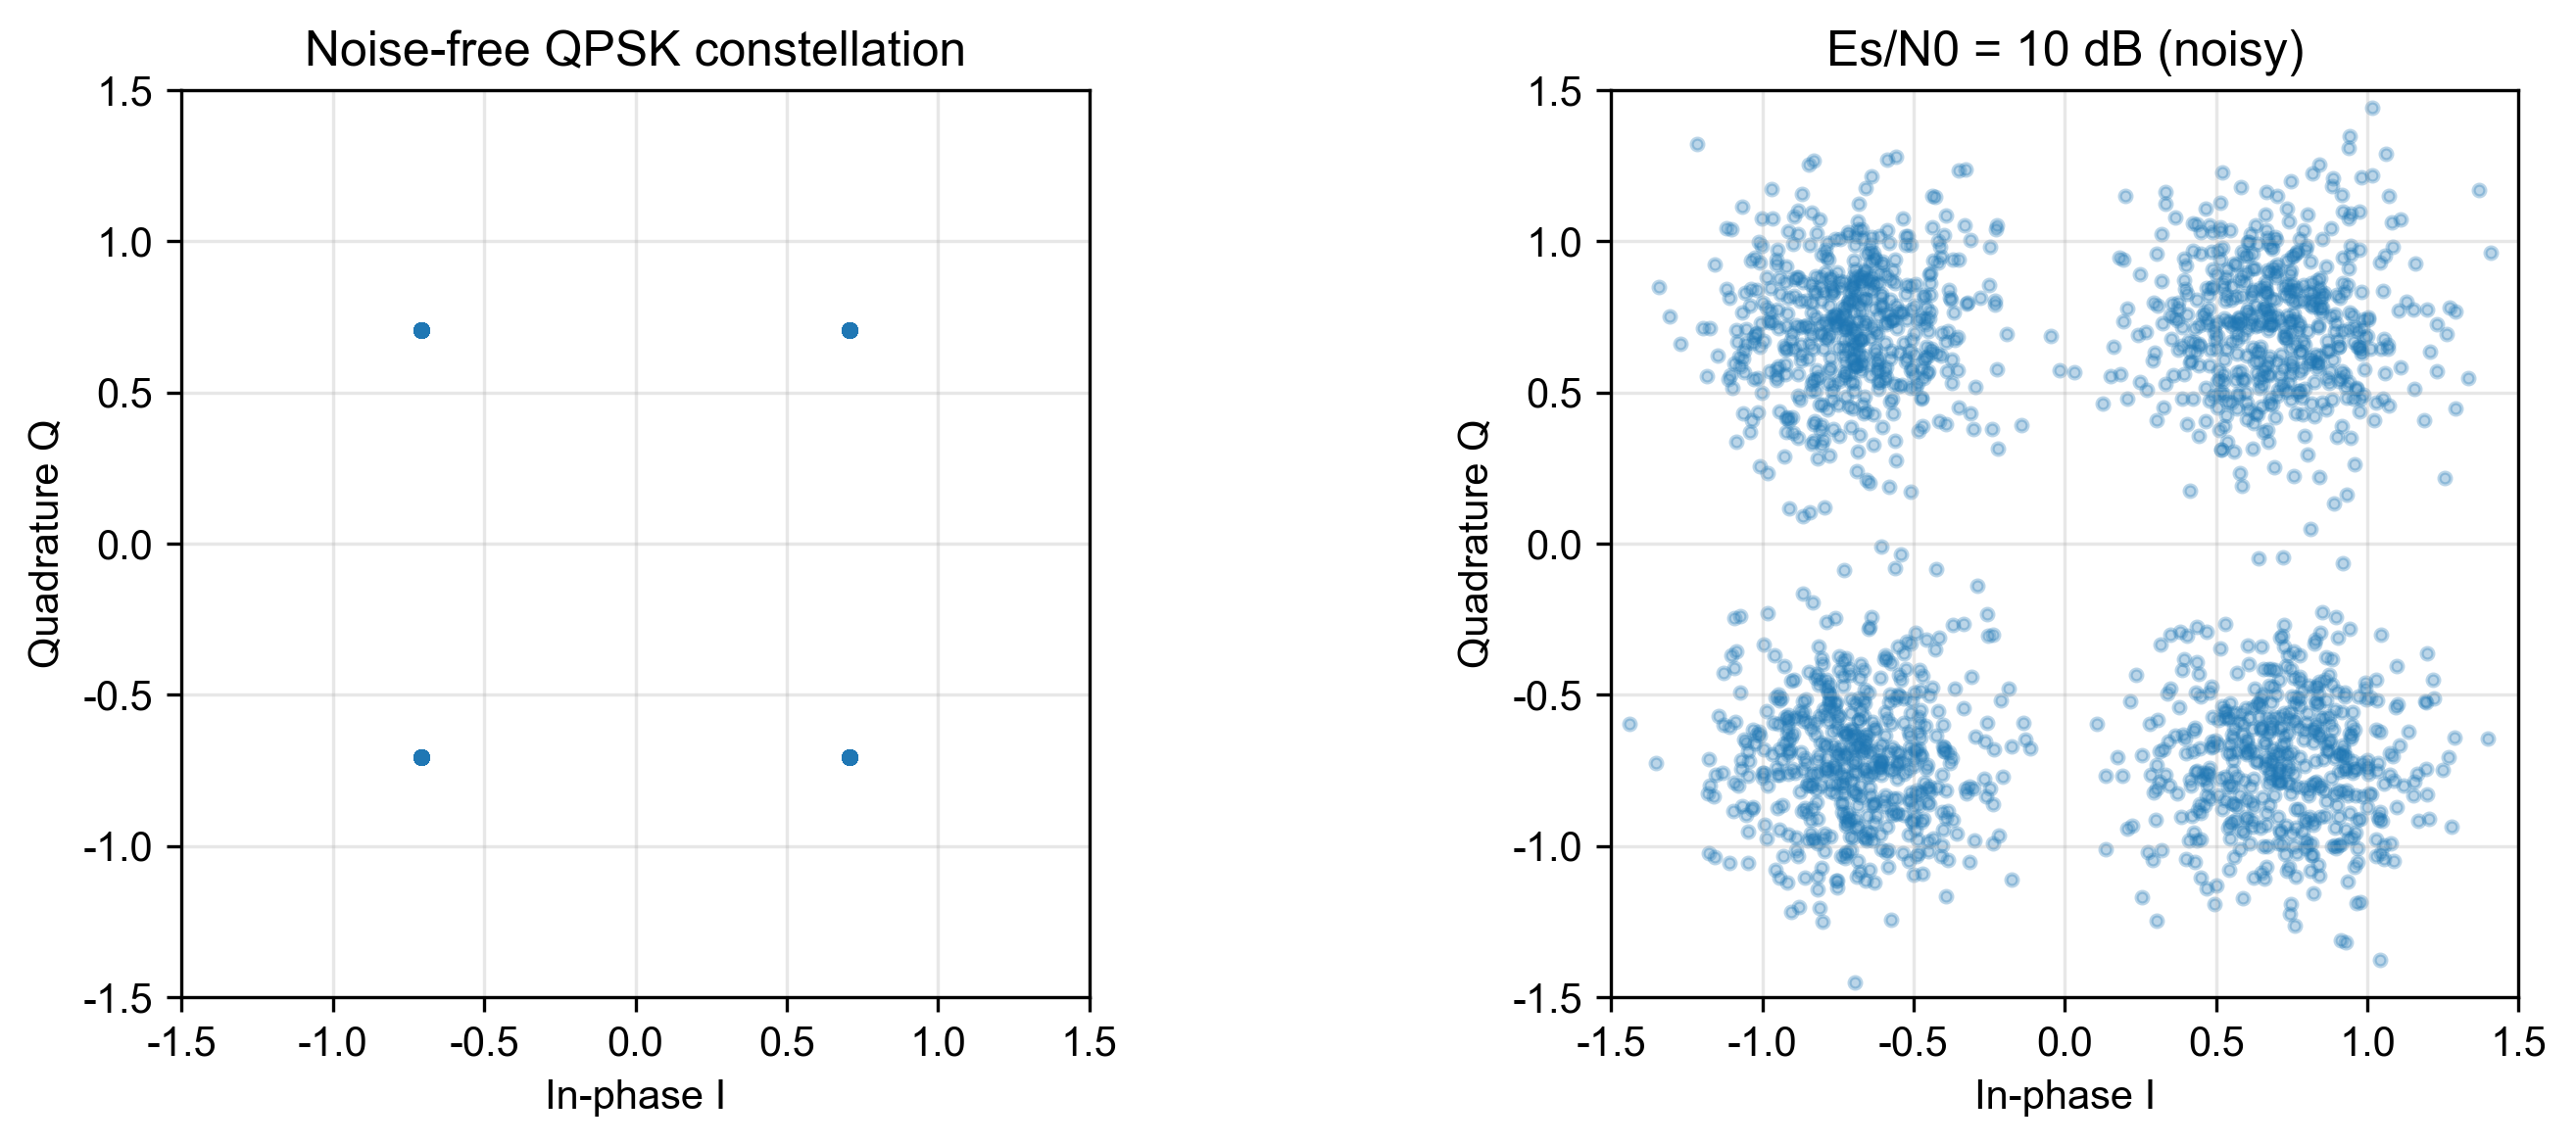

Eb/N0 =  0 dB  →  BER = 0.078570
Eb/N0 =  1 dB  →  BER = 0.056595
Eb/N0 =  2 dB  →  BER = 0.037895
Eb/N0 =  3 dB  →  BER = 0.022835
Eb/N0 =  4 dB  →  BER = 0.012355
Eb/N0 =  5 dB  →  BER = 0.006130
Eb/N0 =  6 dB  →  BER = 0.002360
Eb/N0 =  7 dB  →  BER = 0.000710
Eb/N0 =  8 dB  →  BER = 0.000215
Eb/N0 =  9 dB  →  BER = 0.000015
Eb/N0 = 10 dB  →  BER = 0.000010


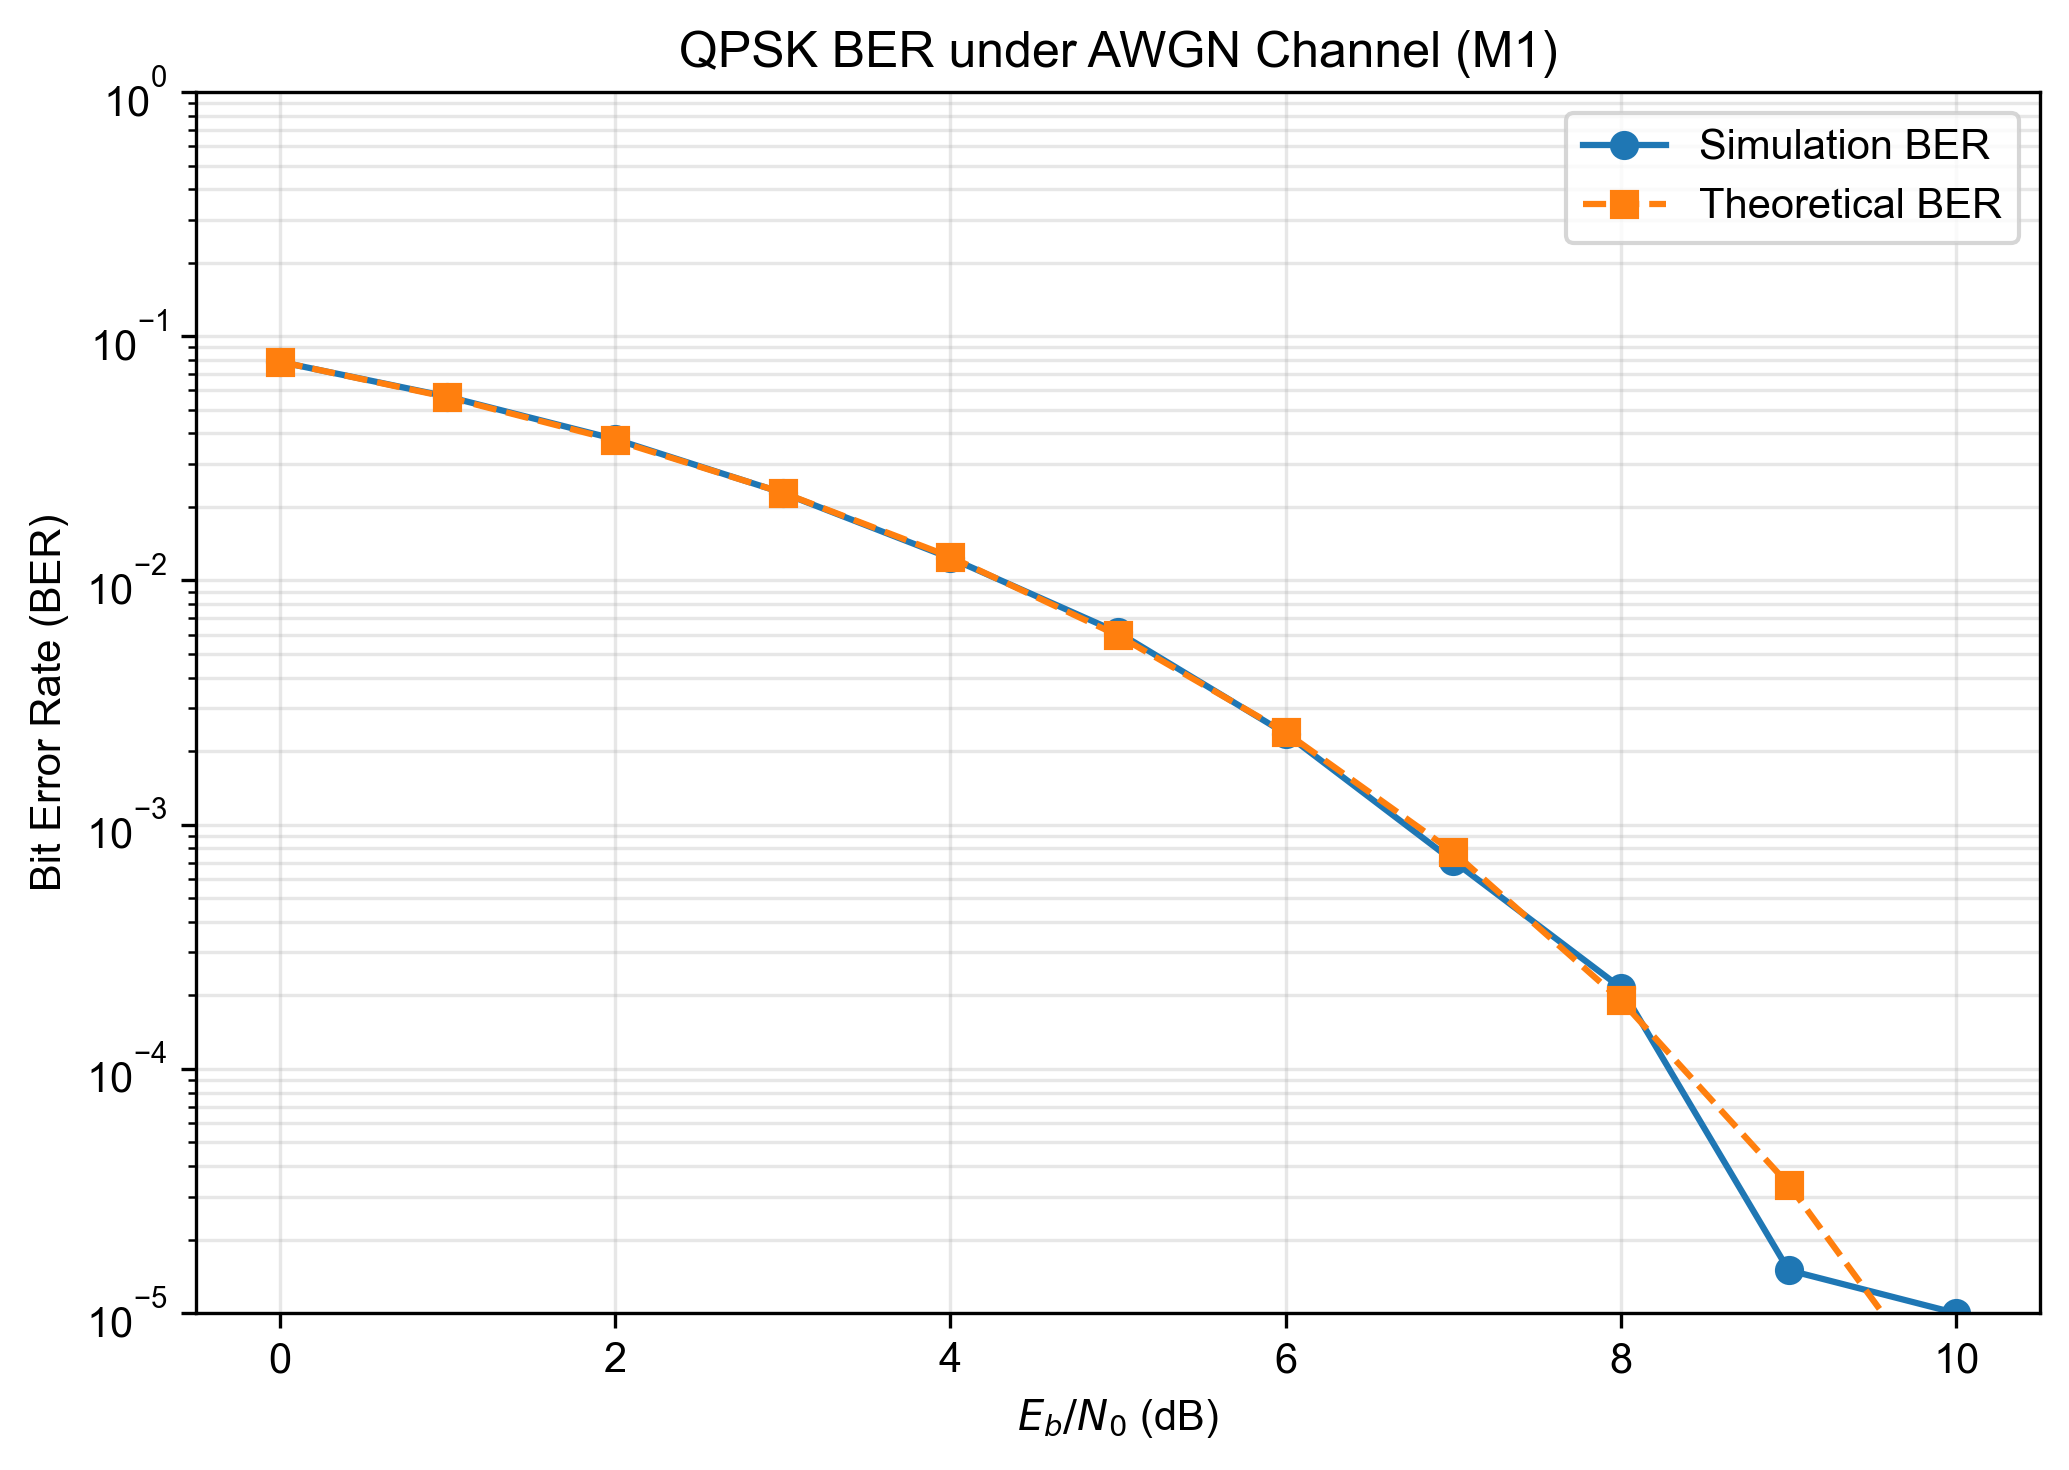


验收：BER 随 Eb/N0 单调下降，仿真点与理论曲线基本重合 → M1 达成


In [4]:
"""
W2 · 数字调制与误码率（里程碑 M1）
生成随机比特 → QPSK 映射 → 加复高斯噪声 → 硬判决 → 统计 BER
运行：python w2_qpsk_ber.py
产出：figures/w2_constellation.png, figures/w2_ber_vs_ebn0.png
"""
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

# ========== 论文风格字体配置（修复减号警告，英文期刊通用Arial） ==========
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['axes.unicode_minus'] = False   # 关闭unicode长减号，消除U+2212警告
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
os.makedirs('figures', exist_ok=True)


def bits_to_qpsk(bits):
    """比特对 → QPSK 符号。映射规则：00→(1+1j)/√2, 01→(1-1j)/√2, 10→(-1+1j)/√2, 11→(-1-1j)/√2"""
    b0 = bits[0::2]
    b1 = bits[1::2]
    i = 1 - 2*b0          # 0 → +1, 1 → -1
    q = 1 - 2*b1
    return (i + 1j*q) / np.sqrt(2)


def qpsk_to_bits(symbols):
    """QPSK 符号 → 比特（硬判决：实部/虚部 >0 判 1）"""
    b0 = (np.real(symbols) < 0).astype(int)
    b1 = (np.imag(symbols) < 0).astype(int)
    out = np.empty(2*len(symbols), dtype=int)
    out[0::2] = b0
    out[0::2] = b0
    out[1::2] = b1
    return out


def add_awgn(symbols, esn0_db):
    """加复高斯白噪声：噪声方差 sigma^2 = Es/N0；Es=1（符号已归一化）"""
    esn0 = 10**(esn0_db/10)
    sigma2 = 1.0 / esn0
    sigma = np.sqrt(sigma2/2)             # I/Q 两路各分一半方差
    noise = sigma*(np.random.randn(len(symbols)) + 1j*np.random.randn(len(symbols)))
    return symbols + noise


# ===== 固定种子保证可复现 =====
np.random.seed(42)
N_BITS = 200_000                          # 比特数（足够多，BER 曲线才平滑）
bits = np.random.randint(0, 2, N_BITS)
tx = bits_to_qpsk(bits)

# ===== 图 1：星座图（无噪声 vs 有噪声）=====
rx_clean = tx
rx_noisy = add_awgn(tx, esn0_db=10)

fig, ax = plt.subplots(1, 2, figsize=(10, 4), dpi=300) # dpi拉高到300，论文高清图
ax[0].scatter(rx_clean[::50].real, rx_clean[::50].imag, s=8, alpha=0.5)
ax[0].set_aspect('equal')
ax[0].set_xlim(-1.5, 1.5); ax[0].set_ylim(-1.5, 1.5)
ax[0].set_title('Noise-free QPSK constellation')
ax[0].set_xlabel('In-phase I'); ax[0].set_ylabel('Quadrature Q')
ax[1].scatter(rx_noisy[::50].real, rx_noisy[::50].imag, s=8, alpha=0.3)
ax[1].set_aspect('equal')
ax[1].set_xlim(-1.5, 1.5); ax[1].set_ylim(-1.5, 1.5)
ax[1].set_title('Es/N0 = 10 dB (noisy)')
ax[1].set_xlabel('In-phase I'); ax[1].set_ylabel('Quadrature Q')
plt.tight_layout()
plt.savefig('figures/w2_constellation.png', bbox_inches='tight')
plt.show()

# ===== 图 2：BER vs Eb/N0（里程碑 M1）=====
# QPSK：Es = 2Eb，所以 Es/N0(dB) = Eb/N0(dB) + 10*log10(2) ≈ Eb/N0 +3.01 dB
ebn0_list = np.arange(0, 11, 1)           # 0~10 dB
ber_list = []
for eb in ebn0_list:
    esn0_db = eb + 10*np.log10(2)
    rx = add_awgn(tx, esn0_db)
    rx_bits = qpsk_to_bits(rx)
    ber = np.mean(rx_bits != bits)
    ber_list.append(ber)
    print(f"Eb/N0 = {eb:2d} dB  →  BER = {ber:.6f}")

# 理论曲线：QPSK 相干检测 BER = Q(sqrt(2*Eb/N0)) = 0.5*erfc(sqrt(Eb/N0))
ebn0_lin = 10**(ebn0_list/10)
ber_theory = 0.5*erfc(np.sqrt(ebn0_lin))

fig, ax = plt.subplots(figsize=(7, 5), dpi=300)
ax.semilogy(ebn0_list, ber_list, 'o-', label='Simulation BER')
ax.semilogy(ebn0_list, ber_theory, 's--', label='Theoretical BER')
ax.set_xlabel('$E_b/N_0$ (dB)')
ax.set_ylabel('Bit Error Rate (BER)')
ax.set_title('QPSK BER under AWGN Channel (M1)')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
ax.set_ylim(1e-5, 1)
plt.tight_layout()
plt.savefig('figures/w2_ber_vs_ebn0.png', bbox_inches='tight')
plt.show()

print("\n验收：BER 随 Eb/N0 单调下降，仿真点与理论曲线基本重合 → M1 达成")
